# Target engineering

**Many models forecast the changes in a series better than the series itself, but the forecast you score has to be turned back into values, using only the past and without a bias.**

This chapter builds `timegym.target`: helpers that turn a series into labels a regressor can learn from, differences of any order, lag or fraction, and four transforms that a pipeline fits on each history and undoes on each forecast (logarithms, a Box-Cox power, differences, and a chain of them).

Below we see what each kind of difference removes from a series with a trend and a cycle, let a model that can make neither forecast the yearly changes instead, and check on three kinds of series when that helps and when it hurts. Then fractional differences, how a forecast of logarithms comes back, how a transform is saved for replay, and the mistakes the transforms refuse.

**Development notebook.** The collapsed cells are the source of `timegym/target.py`; expand them to edit, then follow the [build workflow](README.md#develop-the-package-here).

In [1]:
#| default_exp target

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

%matplotlib inline
plt.rcParams.update({'figure.figsize': (12, 4), 'figure.dpi': 110, 'font.size': 11,
                     'figure.facecolor': 'white', 'axes.facecolor': 'white',
                     'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': False, 'legend.frameon': False, 'axes.titlelocation': 'left'})
pd.set_option('display.max_colwidth', None)


def plot_forecast(ax, case, forecast, title, show_last=48):
    # Gray dots for the data, a thin line for the answer key, blue crosses for the forecast.
    past = case.task.context.iloc[-show_last:, 0]
    ax.scatter(past.index, past, s=10, color='0.65', label='History')
    ax.scatter(case.observed.index, case.observed.iloc[:, 0], s=16, color='0.45',
               label='What actually happened')
    ax.plot(case.reference.index, case.reference.mean[:, 0], color='0.5', lw=0.9, label='Answer key')
    if forecast.quantiles is not None:
        ax.fill_between(forecast.index, forecast.quantiles[:, 0, 0], forecast.quantiles[:, 0, -1],
                        color='#0000CC', alpha=0.1, lw=0, label='Forecast, 10% to 90%')
    ax.scatter(forecast.index, forecast.point[:, 0], marker='x', s=24, linewidths=1.1,
               color='#0000CC', label='Forecast', zorder=4)
    ax.axvline(forecast.index[0] - 0.5, color='#0000CC', ls='--', lw=0.9)
    ax.set(title=title, xlabel='Time step')


def error_against_answer_key(forecast, case):
    # Mean squared distance from the forecast to the answer key, over every step.
    return float(((forecast.point - case.reference.mean) ** 2).mean())

## Labels and differences

The first cells are plain functions. Each treats every column on its own and returns a new copy, leaving the input unchanged.

### Imports

In [3]:
#| export target
from __future__ import annotations

from typing import TypeVar
from numpy.typing import NDArray

import numpy as np
import pandas as pd

_Pandas = TypeVar("_Pandas", pd.Series, pd.DataFrame)


In [4]:
#| export target
from timegym._internal import positive_int


### Labels for several steps ahead (`multioutput_target`)

A regressor learns from rows of inputs and labels. For each column, `multioutput_target` adds the values 1 to `horizon` rows ahead as new columns named `y_t+1`, `y_t+2`, and so on. They are labels: never give them to the model as inputs. Rows without a full set of labels are dropped unless `dropna=False`, and offsets count rows, not calendar time.

In [5]:
#| export target
def multioutput_target(
    df: pd.DataFrame, horizon: int = 10, dropna: bool = True
) -> pd.DataFrame:
    """Append future labels {column}_t+{h} for h=1..horizon, by source column.

    Retain the original columns without mutation; future columns are supervised
    labels and must never enter the predictor matrix. Offsets count rows, not
    calendar durations. dropna=True removes rows missing any value; False keeps
    the index and incomplete tail labels. Existing generated names raise.
    This constructs labels, not a multioutput forecasting adapter.
    """
    if not isinstance(df, pd.DataFrame):
        raise TypeError("df must be a pandas DataFrame")
    if not df.columns.is_unique:
        raise ValueError("df columns must be unique")
    horizon = positive_int(horizon, "horizon")
    df = df.copy()
    for col in df.columns:
        for h in range(1, 1 + horizon):
            name = f"{col}_t+{h}"
            if name in df.columns:
                raise ValueError(f"Future target column already exists: {name}")
            df[name] = df[col].shift(-h)
    return df.dropna() if dropna else df


### The next value (`onestep_target`)

Only `y_t+1`: the label of a model that forecasts one step and is then fed its own forecast.

In [6]:
#| export target
def onestep_target(df: pd.DataFrame, dropna: bool = True) -> pd.DataFrame:
    """Append each next-row label with multioutput_target's copy/missing contract.

    A recursive forecaster can train on these labels; the helper itself does
    not fit a model or feed predictions back into future inputs.
    """
    return multioutput_target(df, horizon=1, dropna=dropna)


### One chosen step ahead (`step_ahead_target`)

Only `y_t+step`: the label of a model that forecasts that one step directly. The reductions in [Forecasting models](06_forecasting_models.ipynb) build their own labels from lag windows; these helpers are for building a training table by hand.

In [7]:
#| export target
def step_ahead_target(
    df: pd.DataFrame, step: int = 5, dropna: bool = True
) -> pd.DataFrame:
    """Append only the label step rows ahead for each original column.

    Keep original columns and never mutate the input. dropna=True removes rows
    missing any original or future value; False retains the incomplete tail.
    Generated names must not collide. This supplies labels for a chosen horizon,
    not a direct forecasting adapter.
    """
    if not isinstance(df, pd.DataFrame):
        raise TypeError("df must be a pandas DataFrame")
    if not df.columns.is_unique:
        raise ValueError("df columns must be unique")
    step = positive_int(step, "step")
    df = df.copy()
    for col in df.columns:
        name = f"{col}_t+{step}"
        if name in df.columns:
            raise ValueError(f"Future target column already exists: {name}")
        df[name] = df[col].shift(-step)
    return df.dropna() if dropna else df


### Weights for a fractional difference (`fractional_weights`)

A difference of order `d` applies (1 - B)^d, where B moves a series one step back. A whole `d` has a few terms; a `d` between 0 and 1 has infinitely many, with weights that shrink slowly. This returns the first `lags` of them, newest first, starting with 1.

In [8]:
#| export target
def fractional_weights(d: float, lags: int) -> NDArray[np.float64]:
    """Return (lags, 1) binomial coefficients of (1-B)^d, newest first.

    d may be any finite real order; lags includes the current observation's
    coefficient 1. The array is a finite truncation, not an infinite filter.
    """
    lags = positive_int(lags, "lags")
    if isinstance(d, (bool, np.bool_)):
        raise ValueError("d must be finite and real")
    d = float(d)
    if not np.isfinite(d):
        raise ValueError("d must be finite")
    weights = [1.0]
    for k in range(1, lags):
        weights.append(-weights[-1] * (d - k + 1) / k)
    return np.asarray(weights).reshape(-1, 1)


### Fractional differences (`fractional_differencing`)

Applies those weights to the last `fractional_coefficients` values (the current one included), spaced `lag` rows apart, and drops the first rows, which lack that much history. Cutting the weights off is an approximation: more coefficients come closer to the exact difference.

In [9]:
#| export target
def fractional_differencing(
    series: _Pandas, order: float, fractional_coefficients: int, *, lag: int = 1
) -> _Pandas:
    """Apply a finite binomial approximation to (1-B^lag)^order.

    Discard only the initial (fractional_coefficients-1)*lag rows that do not
    have a full history. Missing observations inside the series propagate.
    Transform all columns independently, retaining pandas type and labels;
    never mutate the input. Order zero returns a copy without trimming.
    Restore the original target scale in the model before forecast evaluation.
    """
    if not isinstance(series, (pd.Series, pd.DataFrame)):
        raise TypeError("series must be a pandas Series or DataFrame")
    if isinstance(order, (bool, np.bool_)):
        raise ValueError("order must be finite and nonnegative")
    count = positive_int(fractional_coefficients, "fractional_coefficients")
    lag = positive_int(lag, "lag")
    order = float(order)
    if not np.isfinite(order) or order < 0:
        raise ValueError("order must be finite and nonnegative")
    if order == 0:
        return series.copy()
    weights = fractional_weights(order, count)[:, 0]
    result = sum(weights[k] * series.shift(k * lag) for k in range(count))
    return result.iloc[(count - 1) * lag :]


### Differences of any order and lag (`differencing`)

`order` counts how many times to difference and `lag` how far apart the two values are. `order=1` is the change from one row to the next, `order=2` the change in that change, and `order=1, lag=12` the change since the same month a year earlier. They are easy to mix up: `order=2` is not a change over two steps. Each whole difference drops `lag` rows from the start; a fractional order goes to `fractional_differencing`.

In [10]:
#| export target
def differencing(
    series: _Pandas,
    order: float = 1,
    fractional_coefficients: int = 10,
    *,
    lag: int = 1
) -> _Pandas:
    """Apply repeated lag differences; order is not a lag distance.

    order=2 means y[t]-2*y[t-lag]+y[t-2*lag]. For a seasonal first difference
    use order=1, lag=period. Order zero returns a copy unchanged. Noninteger
    orders use the explicitly truncated fractional approximation.
    Return the same pandas type and labels, trimming order*lag warmup rows for
    integer orders. Internal missing values propagate. All columns are treated
    independently without mutation. fractional_coefficients is used only for
    noninteger orders; lag counts rows, not calendar durations.
    """
    if not isinstance(series, (pd.Series, pd.DataFrame)):
        raise TypeError("series must be a pandas Series or DataFrame")
    lag = positive_int(lag, "lag")
    if isinstance(order, (bool, np.bool_)):
        raise ValueError("order must be a finite nonnegative number")
    order = float(order)
    if not np.isfinite(order) or order < 0:
        raise ValueError("order must be a finite nonnegative number")
    if order.is_integer():
        result = series.copy()
        for _ in range(int(order)):
            result = result.diff(periods=lag)
        return result.iloc[int(order) * lag :]
    return fractional_differencing(series, order, fractional_coefficients, lag=lag)


## Transforms a pipeline can undo

A reversible transform changes what the model learns from, then turns the model's forecast back. `fit_transform(history)` fits it on one history and returns what the model sees; `inverse_transform(forecast)` returns the forecast in the original units. Each fit uses that history alone and keeps only what undoing needs: the series names, the Box-Cox powers, or the last values a difference used. A [pipeline](07_pipeline.ipynb) given `target_transform=` refits a fresh copy on every history.

In [11]:
#| export target
import dataclasses
from collections.abc import Sequence

from scipy import optimize, special, stats

from timegym._internal import _real_array
from timegym.contracts import Forecast

### What every transform checks before undoing

A forecast is turned back only if the transform has been fitted, the forecast passes its output checks, and it holds the same series in the same order as the history. For logs and Box-Cox, sample paths and quantiles come back value by value, so quantiles stay in order. The point needs a rule, because the average does not come back that way: it is the average of the turned-back paths; without paths, the turned-back median; without either, the turned-back point, read as a median.

In [12]:
#| export target
def _context_values(context: pd.DataFrame) -> NDArray[np.float64]:
    if not isinstance(context, pd.DataFrame):
        raise TypeError("context must be a pandas DataFrame")
    values = _real_array(context.to_numpy(), "context")
    if values.size == 0 or not np.isfinite(values).all():
        raise ValueError("context must contain finite numeric values")
    return values


def _positive_values(context: pd.DataFrame, owner: str) -> NDArray[np.float64]:
    values = _context_values(context)
    nonpositive = values <= 0
    if nonpositive.any():
        column = int(np.argmax(nonpositive.any(axis=0)))
        row = int(np.argmax(nonpositive[:, column]))
        raise ValueError(
            f"{owner} requires strictly positive context values; target {context.columns[column]!r} "
            f"has {int(nonpositive[:, column].sum())} nonpositive value(s), the first at index "
            f"{context.index[row]!r}")
    return values


class _TargetTransform:
    """Configuration, fitted state, and forecast checks shared by bundled transforms."""

    def params(self) -> dict:
        return {}

    def clone_unfitted(self):
        return type(self)(**self.params())

    def _fitted_on(self, context: pd.DataFrame) -> None:
        self.target_names_ = tuple(context.columns)

    def _check_forecast(self, forecast: Forecast) -> Forecast:
        """Return the forecast to invert; unnamed series are the fitted context's."""
        if not hasattr(self, "target_names_"):
            raise ValueError(f"Call {type(self).__name__}.fit_transform(context) before inverse_transform")
        if not isinstance(forecast, Forecast):
            raise TypeError("inverse_transform requires a timegym.Forecast")
        if forecast.target_names is None:
            forecast = dataclasses.replace(forecast, target_names=self.target_names_)
        problems = sorted({problem["code"] for problem in forecast.validate()})
        if problems:
            raise ValueError(f"Cannot invert a forecast that violates its contract: {', '.join(problems)}")
        if tuple(forecast.target_names) != self.target_names_:
            raise ValueError("Forecast targets or their order differ from the fitted context")
        return forecast


def _invert_elementwise(forecast: Forecast, inverse) -> Forecast:
    """Map every output through an increasing inverse ``inverse(values, target_axis)``.

    Samples and quantiles map elementwise, so quantiles stay ordered. The
    inverse of a transformed-scale mean is not the original-scale mean: a
    point becomes the mean of the inverted samples, else the inverted 0.5
    quantile, else the inverted point read as a transformed-scale median.
    """
    levels = tuple(float(level) for level in forecast.levels)
    samples = None if forecast.samples is None else inverse(_real_array(forecast.samples, "samples"), -1)
    quantiles = None if forecast.quantiles is None else inverse(_real_array(forecast.quantiles, "quantiles"), -2)
    point = None
    if forecast.point is not None:
        if samples is not None:
            point = samples.mean(axis=0)
        elif quantiles is not None and 0.5 in levels:
            point = quantiles[..., levels.index(0.5)]
        else:
            point = inverse(_real_array(forecast.point, "point"), -1)
    return Forecast(index=forecast.index.copy(), point=point, quantiles=quantiles, levels=levels,
                    samples=samples, target_names=tuple(forecast.target_names))

### Logarithms (`LogTransform`)

For a strictly positive series whose swings grow with its level. A history with a zero or a negative value is refused, naming the first one.

In [13]:
#| export target
class LogTransform(_TargetTransform):
    """Natural logarithm of a strictly positive target, inverted by exp.

    Samples and quantiles invert elementwise. exp(mean of logs) is not the
    original-scale mean, so the inverted point is the mean of exp(samples),
    else exp of the 0.5 quantile, else exp of the point read as a median.
    """

    def fit_transform(self, context: pd.DataFrame) -> pd.DataFrame:
        """Record the target names and return the log of a strictly positive context."""
        values = _positive_values(context, "LogTransform")
        self._fitted_on(context)
        return pd.DataFrame(np.log(values), index=context.index.copy(), columns=context.columns.copy())

    def inverse_transform(self, forecast: Forecast) -> Forecast:
        """Return a forecast that meets its contract on the original scale."""
        forecast = self._check_forecast(forecast)
        return _invert_elementwise(forecast, lambda values, axis: np.exp(values))

### A power estimated from the history (`BoxCoxTransform`)

Box-Cox applies a power λ to each series, estimated from the history alone: λ = 1 keeps the shape and λ = 0 is the logarithm. λ is kept between -1 and 2, because on a short history an extreme estimate can leave ordinary forecasts with no value to turn back to; such a forecast raises an error.

In [14]:
#| export target
def _box_cox_lambda(values: NDArray[np.float64]) -> float:
    """Maximize the Box-Cox profile likelihood over [-1, 2], from reciprocal to square."""
    result = optimize.minimize_scalar(lambda power: -stats.boxcox_llf(power, values),
                                      bounds=(-1.0, 2.0), method="bounded")
    return float(result.x)


class BoxCoxTransform(_TargetTransform):
    """Box-Cox transform with one lambda per target, fitted by maximum likelihood on the context.

    The lambdas are recomputed for every context and never see future values.
    Each lies in [-1, 2]: on short contexts the unbounded estimate can be so
    extreme that ordinary forecast noise has no preimage. Inversion follows
    LogTransform's point rule. A transformed value v with lambda * v + 1 <= 0
    has no Box-Cox preimage, and inverting it raises.
    """

    def fit_transform(self, context: pd.DataFrame) -> pd.DataFrame:
        """Fit one lambda per target on this context and return the transformed context."""
        values = _positive_values(context, "BoxCoxTransform")
        constant = np.ptp(values, axis=0) == 0
        if constant.any():
            raise ValueError(f"Box-Cox lambda is not identified for target {context.columns[np.argmax(constant)]!r}, "
                             "which is constant in the context")
        self.lambdas_ = np.array([_box_cox_lambda(column) for column in values.T])
        self._fitted_on(context)
        return pd.DataFrame(special.boxcox(values, self.lambdas_), index=context.index.copy(),
                            columns=context.columns.copy())

    def inverse_transform(self, forecast: Forecast) -> Forecast:
        """Return a forecast that meets its contract on the original scale.

        Raises when a value has no Box-Cox preimage.
        """
        forecast = self._check_forecast(forecast)
        return _invert_elementwise(forecast, self._inverse)

    def _inverse(self, values: NDArray[np.float64], axis: int) -> NDArray[np.float64]:
        lambdas = self.lambdas_.reshape((-1,) + (1,) * (-axis - 1))
        outside = (lambdas != 0) & (lambdas * values + 1 <= 0)
        if outside.any():
            raise ValueError(f"Box-Cox inverse is undefined for {int(outside.sum())} forecast value(s) "
                             "with lambda * value + 1 <= 0")
        return special.inv_boxcox(values, lambdas)

### Differences that remember how to undo themselves (`DifferenceTransform`)

`order` and `lag` mean what they mean in `differencing`, and both must be whole numbers. The transform keeps the last `lag` values at each stage, and undoing adds each forecast change to the value `lag` steps earlier, observed or already forecast, so the forecast must start right after the history. Points and sample paths come back exactly. Quantiles of changes don't add up to quantiles of values, so the quantiles are recomputed from the turned-back paths, and dropped when there are none.

In [15]:
#| export target
class DifferenceTransform(_TargetTransform):
    """Repeated lag differences that keep the context tail needed to undo them.

    ``order`` counts repeated differences and ``lag`` is their distance, as in
    ``differencing``: order=1, lag=12 is a monthly seasonal difference. The
    forecast rows must be the steps that immediately follow the context.
    Points (means) and samples integrate exactly. Marginal quantiles of
    differences do not determine quantiles of their sums, so quantiles are
    recomputed from the integrated samples, or omitted without samples.
    """

    def __init__(self, order=1, lag=1):
        self.order = positive_int(order, "order")
        self.lag = positive_int(lag, "lag")

    def params(self) -> dict:
        """Return the constructor arguments that ``clone_unfitted`` rebuilds from."""
        return {"order": self.order, "lag": self.lag}

    def fit_transform(self, context: pd.DataFrame) -> pd.DataFrame:
        """Keep the context tail needed for inversion and return the differenced context."""
        _context_values(context)
        span = self.order * self.lag
        if len(context) <= span:
            raise ValueError(f"DifferenceTransform(order={self.order}, lag={self.lag}) needs more than "
                             f"{span} context rows")
        self.tails_ = [differencing(context, stage, lag=self.lag).to_numpy(dtype=float)[-self.lag:]
                       for stage in range(self.order)]
        self._fitted_on(context)
        return differencing(context, self.order, lag=self.lag)

    def inverse_transform(self, forecast: Forecast) -> Forecast:
        """Integrate a forecast that meets its contract back to levels.

        Quantiles are recomputed from the integrated samples, or omitted
        without samples.
        """
        forecast = self._check_forecast(forecast)
        point = None if forecast.point is None else self._integrate(_real_array(forecast.point, "point"))
        samples = None if forecast.samples is None else self._integrate(_real_array(forecast.samples, "samples"))
        quantiles, levels = None, ()
        if forecast.quantiles is not None:
            if samples is not None:
                levels = tuple(float(level) for level in forecast.levels)
                quantiles = np.moveaxis(np.quantile(samples, levels, axis=0), 0, -1)
            elif point is None:
                raise ValueError("Quantiles of differences do not determine quantiles of levels; "
                                 "DifferenceTransform needs a point or samples to invert")
        return Forecast(index=forecast.index.copy(), point=point, quantiles=quantiles, levels=levels,
                        samples=samples, target_names=self.target_names_)

    def _integrate(self, values: NDArray[np.float64]) -> NDArray[np.float64]:
        for tail in reversed(self.tails_):
            restored = np.concatenate([np.broadcast_to(tail, values.shape[:-2] + tail.shape), values], axis=-2)
            for step in range(values.shape[-2]):
                restored[..., self.lag + step, :] += restored[..., step, :]
            values = restored[..., self.lag:, :]
        return values

### Several transforms in a row (`ComposedTransform`)

Applies TimeGym's own transforms in order and undoes them in reverse: `ComposedTransform([LogTransform(), DifferenceTransform()])` models log returns. Each member is copied unfitted, so one object never holds two fitted states.

In [16]:
#| export target
class ComposedTransform(_TargetTransform):
    """Apply bundled transforms in order and invert them in reverse order.

    Members are LogTransform, BoxCoxTransform or DifferenceTransform
    instances, copied unfitted so that no instance holds two fitted states.
    """

    def __init__(self, transforms):
        if isinstance(transforms, (str, bytes)) or not isinstance(transforms, Sequence) or not transforms:
            raise ValueError("transforms must be a nonempty sequence of bundled target transforms")
        for transform in transforms:
            if type(transform) not in (LogTransform, BoxCoxTransform, DifferenceTransform):
                raise TypeError("ComposedTransform members must be LogTransform, BoxCoxTransform or "
                                f"DifferenceTransform instances, not {type(transform).__name__}")
        self.transforms = tuple(transform.clone_unfitted() for transform in transforms)

    def params(self) -> dict:
        """Return the constructor arguments that ``clone_unfitted`` rebuilds from."""
        return {"transforms": self.transforms}

    def fit_transform(self, context: pd.DataFrame) -> pd.DataFrame:
        """Fit and apply each member in order, each on the previous member's output."""
        _context_values(context)
        self._fitted_on(context)
        for transform in self.transforms:
            context = transform.fit_transform(context)
        return context

    def inverse_transform(self, forecast: Forecast) -> Forecast:
        """Invert the members in reverse order."""
        forecast = self._check_forecast(forecast)
        for transform in reversed(self.transforms):
            forecast = transform.inverse_transform(forecast)
        return forecast

### Save a transform as data (`transform_config`, `transform_from_config`)

A report stores the transform as plain data, so replay can rebuild it. Only TimeGym's own transforms are rebuilt; any other class, a subclass included, is recorded as external and never rebuilt from the data.

In [17]:
#| export target
_BUNDLED_TRANSFORMS = {kind.__name__: kind for kind in
                       (LogTransform, BoxCoxTransform, DifferenceTransform, ComposedTransform)}


def transform_config(transform) -> dict:
    """Describe a target transform for pipeline configuration and replay.

    Only exact bundled classes are described as ``builtin``; any other object,
    including a subclass, is ``external`` and cannot be rebuilt from data.
    """
    kind = type(transform)
    if _BUNDLED_TRANSFORMS.get(kind.__name__) is not kind:
        return {"kind": "external", "module": kind.__module__, "qualname": kind.__qualname__,
                "reason": "Only bundled target transforms are rebuilt from configuration data."}
    parameters = transform.params()
    if kind is ComposedTransform:
        parameters = {"transforms": [transform_config(member) for member in parameters["transforms"]]}
    return {"kind": "builtin", "class": kind.__name__, "parameters": parameters}


def transform_from_config(config: dict) -> _TargetTransform:
    """Rebuild an unfitted bundled transform from ``transform_config`` output."""
    if not isinstance(config, dict) or set(config) != {"kind", "class", "parameters"} or config["kind"] != "builtin":
        raise ValueError("Replay accepts only bundled target transform descriptions")
    name, parameters = config["class"], config["parameters"]
    if not isinstance(name, str) or name not in _BUNDLED_TRANSFORMS:
        raise ValueError("Target transform class is not in the replay allowlist")
    if name == "ComposedTransform":
        if (not isinstance(parameters, dict) or set(parameters) != {"transforms"}
                or not isinstance(parameters["transforms"], list)):
            raise ValueError("Unexpected or missing target transform parameters")
        members = [transform_from_config(member) for member in parameters["transforms"]]
        if any(isinstance(member, ComposedTransform) for member in members):
            raise ValueError("A composed target transform cannot contain another composition")
        return ComposedTransform(members)
    if not isinstance(parameters, dict) or set(parameters) != set(_BUNDLED_TRANSFORMS[name]().params()):
        raise ValueError("Unexpected or missing target transform parameters")
    return _BUNDLED_TRANSFORMS[name](**parameters)

## Labels: the values a model learns to predict

The simplest target is the value itself, some steps ahead. On a column that counts 0 to 7, the labels are easy to read:

In [18]:
small = pd.DataFrame({'y': np.arange(8, dtype=float)})
labels = multioutput_target(small, horizon=3)
assert step_ahead_target(small, step=3)['y_t+3'].equals(labels['y_t+3'])  # one column of the same table
labels

,y,y_t+1,y_t+2,y_t+3
0,0.0,1.0,2.0,3.0
1,1.0,2.0,3.0,4.0
2,2.0,3.0,4.0,5.0
3,3.0,4.0,5.0,6.0
4,4.0,5.0,6.0,7.0


Each row pairs a value with the three that follow it. The last three rows are gone, because their labels would lie beyond the data. `step_ahead_target(small, step=3)` keeps only the `y_t+3` column, and `onestep_target(small)` only `y_t+1`. At forecast time these columns are the future, so they are labels only.

## What each difference removes

The label doesn't have to be the value. A model that can't follow a trend or a cycle may do better on the changes, if the right difference removes what it can't follow. Think of the steps as months. Here is a series of noise around a line that rises 0.05 per step, plus a cycle of 12 steps (TimeGym's `composite` scenario), and three of its differences:

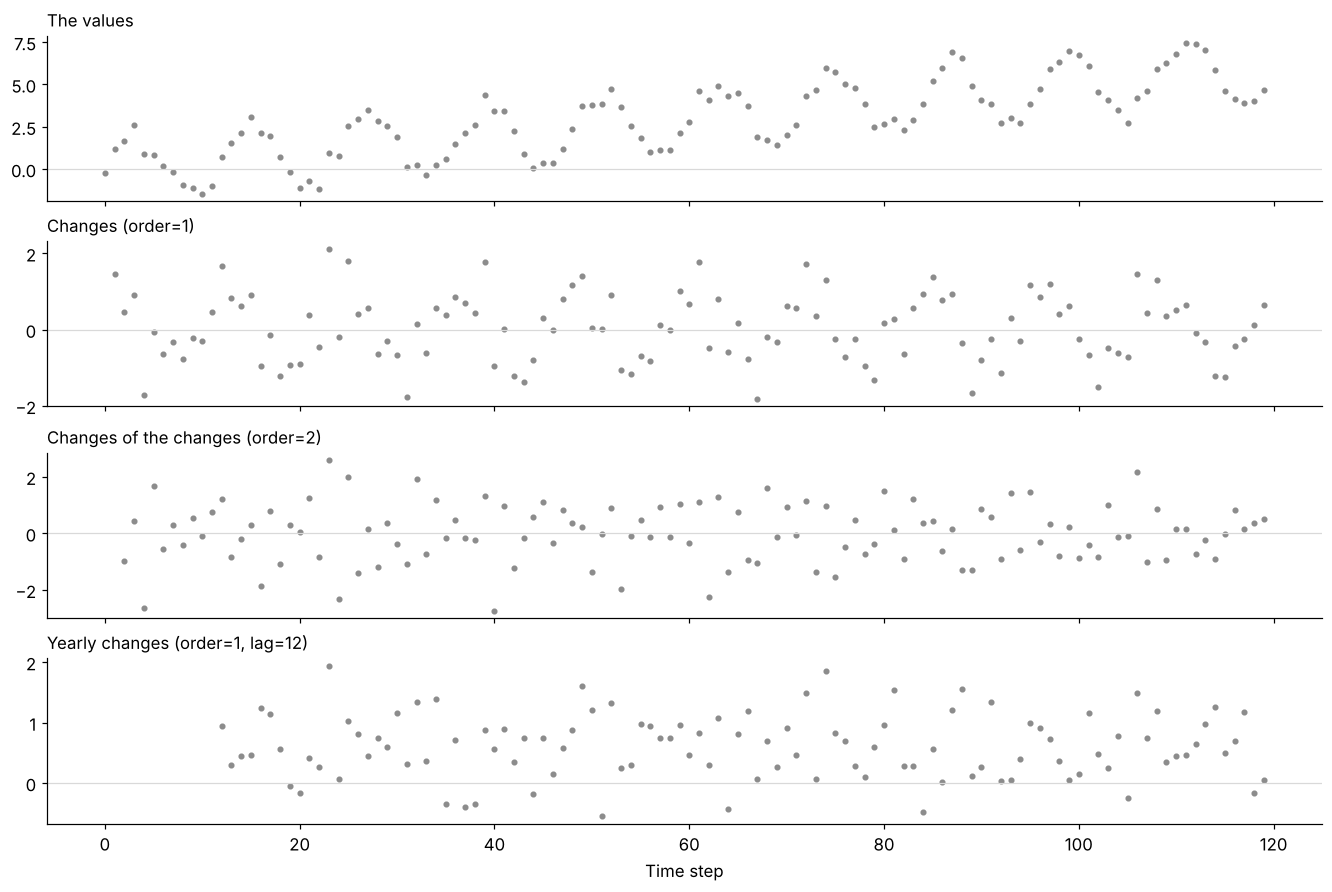

The yearly changes average 0.61: twelve steps of a slope of 0.05.


In [19]:
from timegym import Forecast, GaussianAR1Forecaster, Scenario

trend_cycle = Scenario('composite', context_length=120, horizon=24,
                       parameters={'slope': .05, 'amplitude': 2., 'period': 12., 'sigma': .4})
case = trend_cycle.generate(seed=1)
history = case.task.context['y']
views = {'The values': history,
         'Changes (order=1)': differencing(history),
         'Changes of the changes (order=2)': differencing(history, order=2),
         'Yearly changes (order=1, lag=12)': differencing(history, lag=12)}
fig, axes = plt.subplots(4, 1, figsize=(12, 8), sharex=True, layout='constrained')
for ax, (title, values) in zip(axes, views.items()):
    ax.scatter(values.index, values, s=9, color='0.55')
    ax.axhline(0, color='0.85', lw=0.8)
    ax.set_title(title, fontsize=11)
axes[-1].set_xlabel('Time step')
plt.show()
pd.testing.assert_series_equal(views['Changes of the changes (order=2)'],
                               history.diff().diff().iloc[2:])  # order counts repeated differences
print(f"The yearly changes average {views['Yearly changes (order=1, lag=12)'].mean():.2f}: "
      "twelve steps of a slope of 0.05.")

The change from one step to the next turns the trend into a constant 0.05, too small to see, but the cycle survives. Differencing again does not remove the cycle either: it shrinks it and adds noise, so the cycle hides in the scatter. The yearly change removes both: a cycle of 12 steps repeats itself 12 steps later, and a straight line rises by the same amount every 12 steps. What is left is noise around that amount, 0.61, and 12 fewer rows.

## Forecast the yearly changes, then turn them back

The AR(1) from [Forecasting models](06_forecasting_models.ipynb) bets on mean reversion: shocks fade and the series returns to a level. It can make neither a trend nor a cycle. We fit it once to the values, and once to the yearly changes with `DifferenceTransform(lag=12)`, turning that forecast back into values. Because we generated the series, we know the **answer key**: the best forecast a forecaster that knows the true recipe could make from the same history. Each title gives the forecast's mean squared error against it.

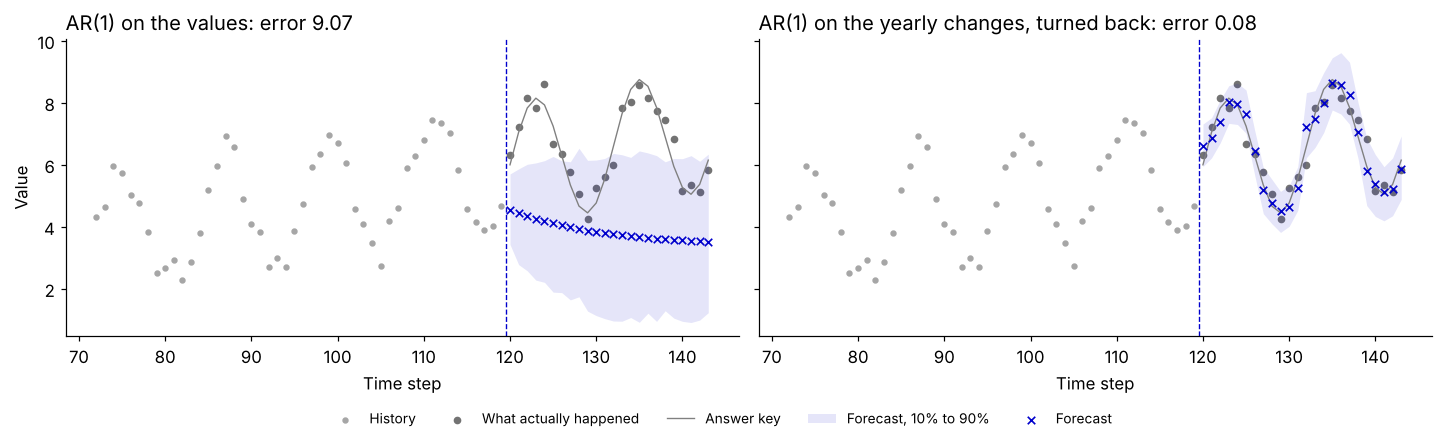

In [20]:
future = case.task.future_index
yearly = DifferenceTransform(lag=12)
yearly_changes = yearly.fit_transform(case.task.context)
changes_forecast = GaussianAR1Forecaster(seed=0).fit(yearly_changes).predict(future)
forecasts = {'AR(1) on the values': GaussianAR1Forecaster(seed=0).fit(case.task.context).predict(future),
             'AR(1) on the yearly changes, turned back': yearly.inverse_transform(changes_forecast)}

fig, axes = plt.subplots(1, 2, figsize=(13, 3.9), sharey=True, layout='constrained')
for ax, (title, forecast) in zip(axes, forecasts.items()):
    plot_forecast(ax, case, forecast, f'{title}: error {error_against_answer_key(forecast, case):.2f}')
axes[0].set_ylabel('Value')
fig.legend(*axes[1].get_legend_handles_labels(), loc='outside lower center', ncol=5, fontsize=9)
plt.show()

On the values, the AR(1) pulls its forecast toward a level it estimates from the history and misses the cycle (error 9.07). On the yearly changes it only has to forecast noise around a constant, which it can; turned back, its forecast follows both the cycle and the trend (0.08). On the right, the band comes from the model's 256 sample paths, each turned back into values.

### Turning back is exact, and needs only the past

What does `inverse_transform` do with the forecast changes? Hand it the true future yearly changes instead, and it should return exactly what happened:

In [21]:
true_changes = differencing(pd.concat([case.task.context, case.observed]), lag=12).loc[future]
exact = yearly.inverse_transform(Forecast(future, point=true_changes.to_numpy()))
np.testing.assert_allclose(exact.point, case.observed.to_numpy())  # the true changes give back what happened
np.testing.assert_array_equal(yearly.tails_[0], case.task.context.to_numpy()[-12:])  # all it kept: the last year
print(f'The true yearly changes, turned back, reproduce all {len(future)} values that happened. '
      'The transform kept only the last 12 values of the history.')

The true yearly changes, turned back, reproduce all 24 values that happened. The transform kept only the last 12 values of the history.


Undoing adds each forecast change to the value 12 steps earlier: an observed value for the first 12 steps, a value already turned back after that. Nothing from the future goes in, so the only error left is the model's.

## When does a difference help?

One draw proves little. Here are 20 draws of three kinds of series, each forecast by the AR(1) on the values, on the changes and on the yearly changes. The table gives the average error against the answer key:

In [22]:
SERIES = {'Trend and cycle': trend_cycle,
          'Random walk: shocks never fade': Scenario('random_walk', context_length=120, horizon=24),
          'Mean reversion (AR(1)): shocks fade': Scenario('ar1', context_length=120, horizon=24,
                                                          parameters={'phi': .8})}
TARGETS = {'AR(1) on the values': None,
           'AR(1) on the changes': DifferenceTransform(),
           'AR(1) on the yearly changes': DifferenceTransform(lag=12)}


def ar1_forecast(draw, transform):
    if transform is None:
        return GaussianAR1Forecaster(seed=0).fit(draw.task.context).predict(draw.task.future_index)
    transform = transform.clone_unfitted()  # a fresh transform for every history
    model = GaussianAR1Forecaster(seed=0).fit(transform.fit_transform(draw.task.context))
    return transform.inverse_transform(model.predict(draw.task.future_index))


rows = []
for kind, scenario in SERIES.items():
    for seed in range(20):
        draw = scenario.generate(seed=seed)
        for target, transform in TARGETS.items():
            rows.append({'kind': kind, 'target': target,
                         'error': error_against_answer_key(ar1_forecast(draw, transform), draw)})
errors = (pd.DataFrame(rows).groupby(['kind', 'target'], sort=False)['error'].mean().unstack()
          .rename_axis(index='Kind of series', columns=None))
assert errors.idxmin(axis=1).tolist() == ['AR(1) on the yearly changes', 'AR(1) on the values',
                                          'AR(1) on the values']  # a difference wins only on the trend and cycle
errors.round(2)

,AR(1) on the values,AR(1) on the changes,AR(1) on the yearly changes
Kind of series,,,
Trend and cycle,8.45,2.86,0.13
Random walk: shocks never fade,0.92,1.43,4.26
Mean reversion (AR(1)): shocks fade,0.12,1.19,2.42


A difference helps when it removes something the model can't make. On the trend and cycle, the yearly change removes both and the error falls from 8.45 to 0.13; the plain change removes only the trend, and the AR(1) still misses the cycle (2.86).

Where the model already fits, a difference costs, and the yearly change costs most (4.26 and 2.42). On mean reversion the AR(1) on the values matches the recipe (0.12); on the changes it loses the level the series returns to and stays near the last value (1.19). Even on a random walk, whose changes are pure noise, the AR(1) does better on the values (0.92 against 1.43): on the changes it estimates an average change from 119 noisy ones, and that small error grows into a drift over 24 steps.

## Fractional differences: part of the way to the changes

A whole difference removes the level completely, which is what costs on mean reversion. An order between 0 and 1 removes only part of it. We difference a random walk of 400 steps with orders from 0 (the values) to 1 (the changes), keeping the default 10 coefficients, and measure how spread out the result is, how strongly each value is correlated with the one before, and how closely the result still follows the walk:

In [23]:
walk = Scenario('random_walk', context_length=400, horizon=1).generate(seed=3).task.context['y']
rows = []
for order in (0, 0.2, 0.4, 0.6, 1):
    result = differencing(walk, order=order)  # 10 coefficients by default
    rows.append({'order': order,
                 'first weights': ', '.join(f'{weight + 0.0:.2f}' for weight in fractional_weights(order, 4)[:, 0]),
                 'sum of the 10 weights': fractional_weights(order, 10).sum() + 0.0,
                 'spread': result.std(),
                 'correlation with the step before': result.autocorr(1),
                 'correlation with the walk': result.corr(walk.loc[result.index])})
fractional = pd.DataFrame(rows).set_index('order')
assert fractional['correlation with the walk'].is_monotonic_decreasing  # a higher order keeps less of the level
fractional.round(2)

,first weights,sum of the 10 weights,spread,correlation with the step before,correlation with the walk
order,,,,,
0.0,"1.00, 0.00, 0.00, 0.00",1.00,6.65,0.99,1.00
0.2,"1.00, -0.20, -0.08, -0.05",0.55,3.79,0.96,0.99
0.4,"1.00, -0.40, -0.12, -0.06",0.28,2.12,0.87,0.92
0.6,"1.00, -0.60, -0.12, -0.06",0.12,1.30,0.59,0.70
1.0,"1.00, -1.00, 0.00, 0.00",0.00,1.01,-0.04,0.09


The sum of the weights is the share of a constant level that passes through: 1 for the values, 0 for the changes, and in between for fractional orders. At 0.4 the result is a third as spread out as the walk (2.12 against 6.65), yet it still follows it closely (correlation 0.92). At 1 it is the changes: noise that barely follows the walk (0.09), with no memory of the step before (-0.04). Cutting the weights off at 10 keeps more of the level than the exact difference would: the weights for 0.4 sum to 0.28, and more coefficients bring that sum closer to 0. Fractional orders are for building inputs: `DifferenceTransform` undoes only whole differences.

## How a forecast of logarithms comes back

`LogTransform` turns a forecast back with exp. Suppose a model forecasts tomorrow's log sales as 4000 sample paths spread evenly around log(100), with a standard deviation of 0.5. We turn that forecast back twice: as it is, and with only its point.

In [24]:
from scipy.stats import norm

sales = pd.DataFrame({'sales': [80., 95., 110., 100.]})
log = LogTransform()
log.fit_transform(sales)
tomorrow = pd.RangeIndex(4, 5)
paths = (np.log(100.) + 0.5 * norm.ppf((np.arange(4000) + 0.5) / 4000)).reshape(-1, 1, 1)
levels = (0.1, 0.5, 0.9)
log_forecast = Forecast(tomorrow, point=paths.mean(axis=0), samples=paths, levels=levels,
                        quantiles=np.moveaxis(np.quantile(paths, levels, axis=0), 0, -1))
back = log.inverse_transform(log_forecast)
point_only = log.inverse_transform(Forecast(tomorrow, point=log_forecast.point))
np.testing.assert_allclose(back.quantiles, np.exp(log_forecast.quantiles))  # quantiles come back exactly
np.testing.assert_allclose(back.point, np.exp(paths).mean(axis=0))  # the point is the average of the turned-back paths
display(pd.Series({'10% quantile': back.quantiles[0, 0, 0], 'Median': back.quantiles[0, 0, 1],
                   '90% quantile': back.quantiles[0, 0, 2], 'Point, from the paths': back.point[0, 0],
                   'Point, from a point only': point_only.point[0, 0]},
                  name='Sales tomorrow').round(1).to_frame())

box_cox = BoxCoxTransform()
box_cox.fit_transform(np.exp(case.task.context / 4))  # positive, and its log is a line plus a cycle
print(f'On a series whose log is a line plus a cycle, Box-Cox estimates a power of '
      f'{box_cox.lambdas_[0]:.2f} from the history (0 is the logarithm).')

,Sales tomorrow
10% quantile,52.7
Median,100.0
90% quantile,189.7
"Point, from the paths",113.3
"Point, from a point only",100.0


On a series whose log is a line plus a cycle, Box-Cox estimates a power of -0.03 from the history (0 is the logarithm).


The quantiles come back exactly: the median of tomorrow's sales is exp(log 100) = 100. The average does not. The exponential stretches high values more than it squeezes low ones, so the average of the 4000 turned-back paths is 113.3, a factor exp(0.5² / 2) = 1.13 above the median, and that average is the point TimeGym returns. Given only a point, TimeGym can't know the spread, so it returns exp of the point and treats it as the median: 100. [Target transforms](../tutorials/04_target_transforms.ipynb) shows how this gap builds up over a real forecast.

Box-Cox estimates its power from the history alone. On a series whose logarithm is a line plus a cycle, it lands close to 0, the logarithm.

## Chain transforms and save them as data

A pipeline's report records its transform, so replay can rebuild it. Here are log returns, a log followed by a change, saved and rebuilt, and then a class of our own:

In [25]:
log_returns = ComposedTransform([LogTransform(), DifferenceTransform()])
saved = transform_config(log_returns)
assert transform_config(transform_from_config(saved)) == saved  # the data rebuild the same transform
print('Saved as', ', then '.join(
    f"{member['class']}({', '.join(f'{key}={value}' for key, value in member['parameters'].items())})"
    for member in saved['parameters']['transforms']))


class MyLog(LogTransform):
    """A subclass is a class of your own."""


mine = transform_config(MyLog())
print(f"A subclass of LogTransform is saved as {mine['kind']}: {mine['reason']}")
try:
    transform_from_config(mine)
except ValueError as refusal:
    print(f'Rebuilding it: {refusal}')

Saved as LogTransform(), then DifferenceTransform(order=1, lag=1)
A subclass of LogTransform is saved as external: Only bundled target transforms are rebuilt from configuration data.
Rebuilding it: Replay accepts only bundled target transform descriptions


The description is plain data with no code in it, so a saved report can be read safely and still rebuild the transform. A transform class you write yourself is recorded by name only; keep its code next to the report.

## Mistakes the transforms refuse

Each of these would otherwise give a wrong forecast or a confusing failure later on. The transforms raise an error instead:

In [26]:
attempts = {
    'Logs of sales with a zero day':
        lambda: LogTransform().fit_transform(pd.DataFrame({'sales': [3., 0., 5.]})),
    'Yearly changes from one year of history':
        lambda: DifferenceTransform(lag=12).fit_transform(case.task.context.iloc[:12]),
    'Turning back the quantiles of the changes alone':
        lambda: yearly.inverse_transform(Forecast(future, quantiles=changes_forecast.quantiles,
                                                  levels=changes_forecast.levels)),
}
refusals = []
for attempt, call in attempts.items():
    try:
        call()
    except ValueError as error:
        refusals.append({'what we tried': attempt, 'what the transform said': str(error)})
assert len(refusals) == len(attempts)  # every one is refused
pd.DataFrame(refusals)

,what we tried,what the transform said
0,Logs of sales with a zero day,"LogTransform requires strictly positive context values; target 'sales' has 1 nonpositive value(s), the first at index 1"
1,Yearly changes from one year of history,"DifferenceTransform(order=1, lag=12) needs more than 12 context rows"
2,Turning back the quantiles of the changes alone,Quantiles of differences do not determine quantiles of levels; DifferenceTransform needs a point or samples to invert


The first is the common one in practice: sales with a zero day can't be logged, and the message names the series and the first such row. The third is a rule, not a gap: quantiles of the changes don't determine quantiles of their sums, so a forecast of changes needs a point or sample paths to come back.

**Limits.** `DifferenceTransform` undoes whole differences only, and only for a forecast that starts right after the history. The comparison table averages 20 draws of three recipes with one simple model: it shows when a difference can help, not which transform your series needs. [Target transforms](../tutorials/04_target_transforms.ipynb) compares logs and no logs on 60 series.

## Change one thing

- Change the cycle's `period` to 10 and keep `lag=12`. Does the yearly difference still remove the cycle?
- Raise mean reversion's `phi` to 0.98 in `SERIES`. Does the AR(1) on the changes catch up with the AR(1) on the values?
- Pass `fractional_coefficients=100` in the fractional table. How closely does order 0.4 still follow the walk?

**Next:** [06 · Forecasting models](06_forecasting_models.ipynb). [Target transforms](../tutorials/04_target_transforms.ipynb) puts these transforms to work on series whose swing grows with their level.